# The Heat Equation


The study and analysis of how heat propagates throughout matter has been an interesting and captivating matter for scientists and engineers during centuries. However, its origins are traced more specifically to physics problems. This topic was addressed in the early 19th century by Fourier, a French mathematician and physicist, who in 1807, proposed a new mathematical way to study heat. His idea was that any temperature distribution could be described as a sum of sine and cosine waves — a method now known as the **Fourier series**.

This approach was groundbreaking at the time, because it introduced the idea that even complex or irregular temperature distributions could be expressed through simple, periodic functions. Though initially controversial, his theory eventually became widely accepted, especially after the publication of his 1822 book *The Analytical Theory of Heat*, where he formally introduced the **heat equation**

### Original Equation and Analytical Solution


The heat equation is a central model in the study of parabolic partial differential equations and often serves as the first step in learning how to solve time-dependent PDEs numerically. Its simplicity and structure make it ideal for exploring how diffusion behaves in a one-dimensional medium.

As discussed in *Numerical Analysis Using R: Solutions to ODEs and PDEs* (Griffiths), the heat equation provides a clear example of how physical principles like thermal diffusion can be translated into mathematical models and then approximated using finite difference schemes or the method of lines.

In its one-dimensional form, and under some assumptions like constant material properties and no internal sources, the equation is written as:

$$
\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2},
$$

where:
- $u(x,t)$ represents the temperature at position $x \in [0, L]$ and time $t \geq 0$.
- $\alpha$ is the thermal diffusivity of the material.

This equation appears early in most textbooks on PDEs and numerical methods, such as *LeVeque (2007)* and *Griffiths (2017)*. It's simple enough to solve by hand but still shows the key ideas behind more complex diffusion processes.

To solve it analytically, we usually assume that the ends of the rod are kept at zero temperature (Dirichlet boundary conditions), and we’re given an initial temperature profile \( f(x) \). The solution can be built by separating variables and writing it as a sum of sine waves that each decay over time:

$$
u(x, t) = \sum_{n=1}^{\infty} B_n \sin\left( \frac{n\pi x}{L} \right) \exp\left( -\alpha \left( \frac{n\pi}{L} \right)^2 t \right),
$$

with each \( B_n \) depending on the initial condition:

$$
B_n = \frac{2}{L} \int_0^L f(x) \sin\left( \frac{n\pi x}{L} \right) dx.
$$

### Uniqueness and Existence of the Solution

Before applying any numerical method, it's essential to know whether the original problem has a well-defined solution. In the context of partial differential equations, this means checking if the problem is *well-posed*, which basically means that it has a solution and that the solution is unique.

For the heat equation with homogeneous Dirichlet boundary conditions and a continuous initial function \( f(x) \), the problem is indeed well-posed. This is a classical result and one of the reasons why the heat equation is such a common example in both theory and applications.

#### Uniqueness

Uniqueness is usually shown using the **maximum principle** for parabolic equations. In short, if two solutions satisfy the same initial and boundary conditions, then their difference also satisfies the heat equation but with zero initial and boundary data. The maximum principle implies that this difference must be zero everywhere, which confirms that the original solution is unique.

#### Existence

Existence can be shown in different ways:

- **Analytically**, by constructing the solution explicitly using separation of variables and Fourier series, as we did in the previous section. This approach is presented in *LeVeque (2007)*.
- **Numerically**, by showing that stable and consistent finite difference schemes converge to a solution as the mesh is refined.
- **Functionally**, in more advanced settings, existence can be proven using energy estimates and weak formulations — though this is beyond our scope here.

In summary, the heat equation problem we are studying is well-posed: it has one and only one smooth solution that depends continuously on the initial data. This justifies the use of numerical methods to approximate it.

### Numerical Scheme: FTCS for the Heat Equation

The heat equation needs numerical solution through a specific method. The continuous equation is:

$$
\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}
$$

The first step requires dividing the domain into smaller sections. The space $[0, L]$ receives division into $\Delta x$ sized intervals and time steps of $\Delta t$. The temperature approximation at position $x_i = i \Delta x$ and time $t^n = n \Delta t$ is denoted as $u_i^n$.

The derivatives receive their approximations through finite difference methods.
The forward difference method provides an approximation of the time derivative as follows:
$$
\frac{u_i^{n+1} - u_i^n}{\Delta t}
$$

The second spatial derivative receives its approximation through the centered difference method:
$$
\frac{u_{i+1}^n - 2u_i^n + u_{i-1}^n}{(\Delta x)^2}
$$

The original equation becomes:
$$
\frac{u_i^{n+1} - u_i^n}{\Delta t} = \alpha \cdot \frac{u_{i+1}^n - 2u_i^n + u_{i-1}^n}{(\Delta x)^2}
$$

The FTCS (Forward Time Centered Space) scheme emerges from solving for $u_i^{n+1}$.
$$
u_i^{n+1} = u_i^n + \lambda \left( u_{i+1}^n - 2u_i^n + u_{i-1}^n \right)
$$

The parameter $\lambda$ equals $\frac{\alpha \Delta t}{(\Delta x)^2}$.

Through this formula we can determine the temperature values for the upcoming time step using the present temperature information. The boundary values at $x = 0$ and $x = L$ stay constant because we enforce Dirichlet boundary conditions.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

L = 1.0
T = 0.5
alpha = 1.0

nx = 50
nt = 8000

dx = L / (nx - 1)
dt = T / nt
x = np.linspace(0, L, nx)
t = np.linspace(0, T, nt)

lambda_ = alpha * dt / dx**2

assert lambda_ <= 0.5, f"Lambda = {lambda_:.3f} is too large; reduce dt or increase nx."



In [ ]:
u0 = np.sin(np.pi * x)
u = np.zeros((nt, nx))
u[0, :] = u0

for n in range(0, nt - 1):
    for i in range(1, nx - 1):
        u[n+1, i] = u[n, i] + lambda_ * (u[n, i+1] - 2*u[n, i] + u[n, i-1])



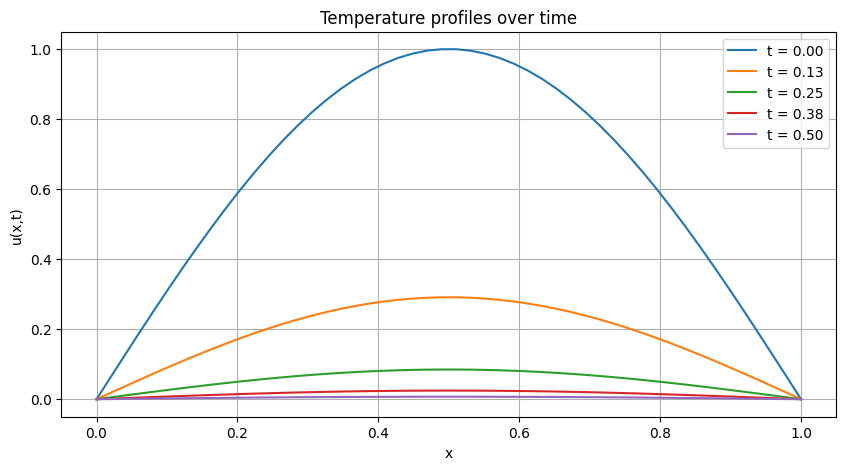

In [9]:
plt.figure(figsize=(10, 5))
for i in [0, nt//4, nt//2, 3*nt//4, nt-1]:
    plt.plot(x, u[i], label=f't = {t[i]:.2f}')
plt.title("Temperature profiles over time")
plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.legend()
plt.grid(True)
plt.show()


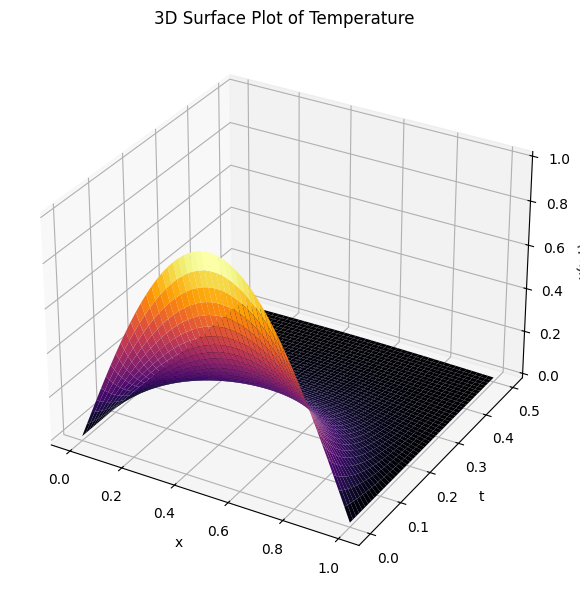

In [10]:
X, T_mesh = np.meshgrid(x, t)
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, T_mesh, u, cmap='inferno')
ax.set_title("3D Surface Plot of Temperature")
ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel("u(x,t)")
plt.tight_layout()
plt.show()


### References

- LeVeque, R. J. (2007). *Finite Difference Methods for Ordinary and Partial Differential Equations: Steady-State and Time-Dependent Problems*. Society for Industrial and Applied Mathematics (SIAM). 

- Griffiths, D. F., & Higham, D. J. (2017). *Numerical Analysis Using R: Solutions to ODEs and PDEs*. Springer. 
